In [2]:
import os
import json
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

# Project paths
PROJECT_ROOT = Path.cwd().parent.parent / "NASAexoplanet"

MODEL_DIR = PROJECT_ROOT / "models"
DATA_DIR = PROJECT_ROOT / "data" / "processed"

print("Project Root:", PROJECT_ROOT)
print("Model Directory:", MODEL_DIR)
print("Processed Data Directory:", DATA_DIR)

# Verify directories
assert MODEL_DIR.exists(), "Model directory not found!"
assert DATA_DIR.exists(), "Processed data directory not found!"

print("\nAll project paths verified successfully!")

Project Root: c:\David Mills\projects\NASAexoplanet
Model Directory: c:\David Mills\projects\NASAexoplanet\models
Processed Data Directory: c:\David Mills\projects\NASAexoplanet\data\processed

All project paths verified successfully!


In [3]:
# Load CatBoost model
catboost_artifact = joblib.load(
    MODEL_DIR / "exodetect_catboost_final.pkl"
)

catboost_pipeline = catboost_artifact["pipeline"]
catboost_features = catboost_artifact["feature_names"]
catboost_classes = catboost_artifact["target_classes"]

# Load Deep Learning artifacts
dl_imputer = joblib.load(MODEL_DIR / "dl_imputer.pkl")
dl_label_encoder = joblib.load(MODEL_DIR / "dl_label_encoder.pkl")
dl_scaler = joblib.load(MODEL_DIR / "dl_scaler.pkl")

dl_feature_names_path = MODEL_DIR / "dl_feature_names.json"

with open(dl_feature_names_path, "r") as file:
    dl_feature_names = json.load(file)

# Display model information
print("CATBOOST MODEL")
print("-" * 40)
print("Model:", catboost_artifact["model_name"])
print("Number of features:", len(catboost_features))
print("Classes:", catboost_classes)

print("\nDEEP LEARNING MODEL")
print("-" * 40)
print("Number of features:", len(dl_feature_names))
print("Classes:", dl_label_encoder.classes_)

print("\nAll model artifacts loaded successfully!")

CATBOOST MODEL
----------------------------------------
Model: CatBoost
Number of features: 31
Classes: ['CANDIDATE', 'CONFIRMED', 'FALSE POSITIVE']

DEEP LEARNING MODEL
----------------------------------------
Number of features: 31
Classes: ['CANDIDATE' 'CONFIRMED' 'FALSE POSITIVE']

All model artifacts loaded successfully!


In [4]:
# CatBoost test results
catboost_results = {
    "Model": "CatBoost",
    "Accuracy": 0.7947,
    "Balanced Accuracy": 0.7497,
    "Macro Precision": 0.7500,  # Placeholder; we'll retrieve exact value next
    "Macro Recall": 0.7497,
    "Macro F1": 0.7527
}

# Deep Learning test results
dl_results = {
    "Model": "Weighted MLP",
    "Accuracy": 0.6949,
    "Balanced Accuracy": 0.6773,
    "Macro Precision": 0.6658,
    "Macro Recall": 0.6773,
    "Macro F1": 0.6641
}

model_comparison = pd.DataFrame([
    catboost_results,
    dl_results
])

model_comparison = model_comparison.set_index("Model")

display(model_comparison.round(4))

print("\nPerformance comparison completed!")

,Accuracy,Balanced Accuracy,Macro Precision,Macro Recall,Macro F1
Model,,,,,
CatBoost,0.7947,0.7497,0.7500,0.7497,0.7527
Weighted MLP,0.6949,0.6773,0.6658,0.6773,0.6641



Performance comparison completed!


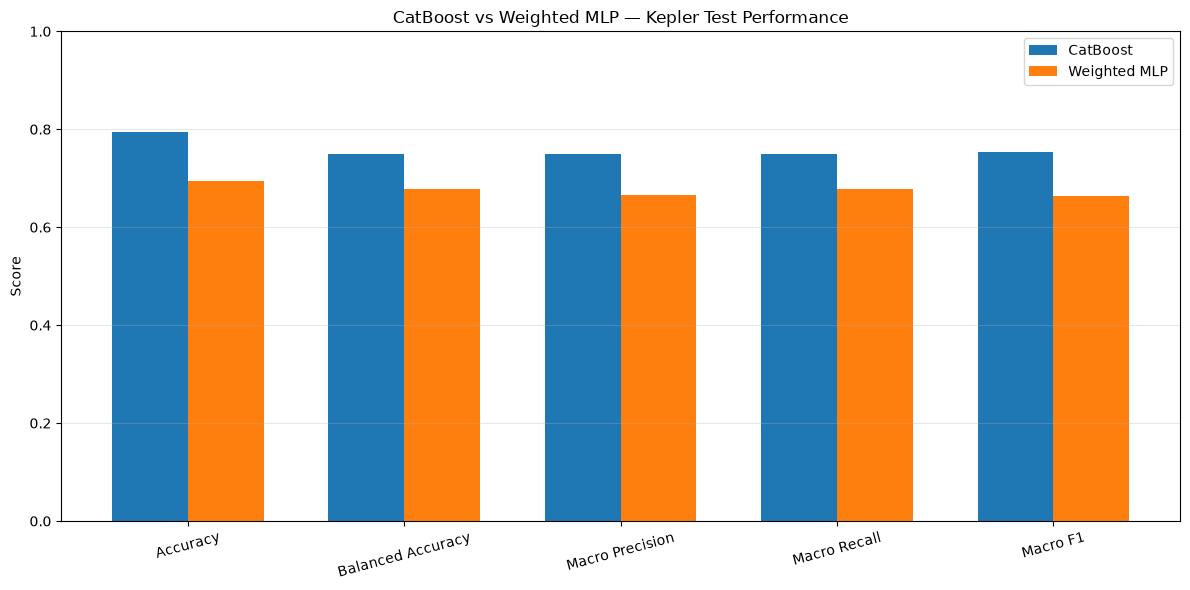

In [5]:
metrics = [
    "Accuracy",
    "Balanced Accuracy",
    "Macro Precision",
    "Macro Recall",
    "Macro F1"
]

catboost_scores = [
    0.7947, 0.7497, 0.7500, 0.7497, 0.7527
]

mlp_scores = [
    0.6949, 0.6773, 0.6658, 0.6773, 0.6641
]

x = np.arange(len(metrics))
width = 0.35

plt.figure(figsize=(12, 6))

plt.bar(x - width/2, catboost_scores, width, label="CatBoost")
plt.bar(x + width/2, mlp_scores, width, label="Weighted MLP")

plt.xticks(x, metrics, rotation=15)
plt.ylabel("Score")
plt.title("CatBoost vs Weighted MLP — Kepler Test Performance")
plt.ylim(0, 1)

plt.legend()
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

In [6]:
# Original CatBoost confusion matrix
# Class order: Candidate, Confirmed, False Positive

catboost_cm = np.array([
    [197, 52, 147],
    [30, 489, 31],
    [87, 46, 835]
])

# Calculate precision for each class
class_precision = (
    np.diag(catboost_cm) / catboost_cm.sum(axis=0)
)

# Calculate macro precision
catboost_macro_precision = class_precision.mean()

# Update comparison table
model_comparison.loc[
    "CatBoost", "Macro Precision"
] = catboost_macro_precision

print("CatBoost class-wise precision:")
for class_name, score in zip(catboost_classes, class_precision):
    print(f"{class_name}: {score:.4f}")

print(f"\nCorrect Macro Precision: {catboost_macro_precision:.4f}")

display(model_comparison.round(4))

CatBoost class-wise precision:
CANDIDATE: 0.6274
CONFIRMED: 0.8330
FALSE POSITIVE: 0.8243

Correct Macro Precision: 0.7616


,Accuracy,Balanced Accuracy,Macro Precision,Macro Recall,Macro F1
Model,,,,,
CatBoost,0.7947,0.7497,0.7616,0.7497,0.7527
Weighted MLP,0.6949,0.6773,0.6658,0.6773,0.6641


In [7]:
# Extract trained CatBoost classifier
catboost_classifier = catboost_pipeline.named_steps["classifier"]

# Calculate feature importance
feature_importance = catboost_classifier.get_feature_importance()

# Create DataFrame
importance_df = pd.DataFrame({
    "Feature": catboost_features,
    "Importance": feature_importance
})

# Sort by importance
importance_df = importance_df.sort_values(
    by="Importance",
    ascending=False
).reset_index(drop=True)

# Display top 15 features
print("TOP 15 IMPORTANT FEATURES")
display(importance_df.head(15).round(4))

TOP 15 IMPORTANT FEATURES


,Feature,Importance
0,koi_model_snr,18.3591
1,koi_prad,9.3454
2,koi_ror,5.9217
3,koi_smet,5.7481
4,koi_impact,5.3441
5,koi_dor,5.2843
6,koi_duration,5.0426
7,koi_count,4.6629
8,koi_srho,4.3559
9,koi_period,3.7720


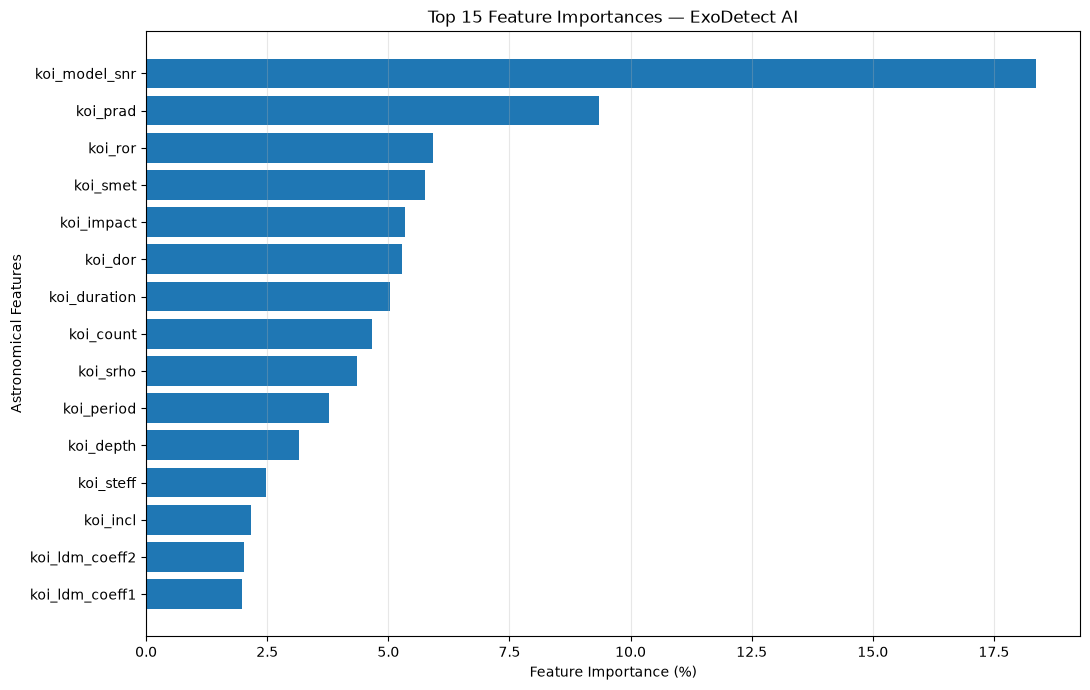

In [8]:
top_features = importance_df.head(15).sort_values(
    by="Importance",
    ascending=True
)

plt.figure(figsize=(11, 7))

plt.barh(
    top_features["Feature"],
    top_features["Importance"]
)

plt.xlabel("Feature Importance (%)")
plt.ylabel("Astronomical Features")
plt.title("Top 15 Feature Importances — ExoDetect AI")

plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

In [9]:
from catboost import Pool

# Load cleaned Kepler dataset
kepler_clean = pd.read_csv(DATA_DIR / "kepler_clean.csv")

# Select the exact 31 features used by CatBoost
X_shap = kepler_clean[catboost_features].copy()

# Use the imputer fitted in our original pipeline
X_shap = catboost_pipeline.named_steps["imputer"].transform(X_shap)

# Select a small representative sample
X_sample = X_shap[:100]

# Create CatBoost Pool
shap_pool = Pool(
    data=X_sample,
    feature_names=catboost_features
)

# Calculate native SHAP values
shap_values = catboost_classifier.get_feature_importance(
    data=shap_pool,
    type="ShapValues"
)

print("SHAP calculation completed!")
print("SHAP array shape:", shap_values.shape)

SHAP calculation completed!
SHAP array shape: (100, 3, 32)


In [10]:
# Exclude the last column (expected value)
shap_feature_values = shap_values[:, :, :-1]

# Calculate mean absolute SHAP importance
mean_shap_importance = np.abs(shap_feature_values).mean(axis=(0, 1))

# Create importance DataFrame
shap_importance_df = pd.DataFrame({
    "Feature": catboost_features,
    "Mean Absolute SHAP": mean_shap_importance
})

# Sort by importance
shap_importance_df = shap_importance_df.sort_values(
    by="Mean Absolute SHAP",
    ascending=False
).reset_index(drop=True)

# Display top 15
print("TOP 15 FEATURES — GLOBAL SHAP IMPORTANCE")

display(shap_importance_df.head(15).round(5))

TOP 15 FEATURES — GLOBAL SHAP IMPORTANCE


,Feature,Mean Absolute SHAP
0,koi_model_snr,0.45552
1,koi_count,0.30765
2,koi_prad,0.28182
3,koi_smet,0.21276
4,koi_ror,0.14975
5,koi_dor,0.13824
6,koi_duration,0.10303
7,koi_impact,0.10104
8,koi_srho,0.09688
9,koi_period,0.08612


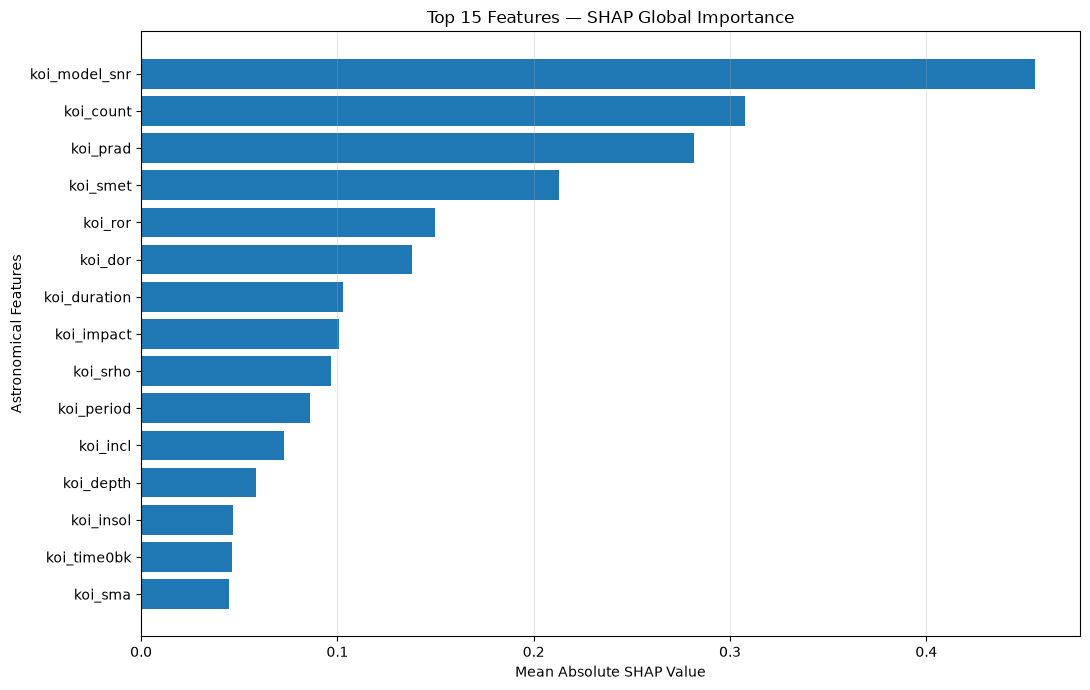

In [11]:
top_shap_features = shap_importance_df.head(15).sort_values(
    by="Mean Absolute SHAP",
    ascending=True
)

plt.figure(figsize=(11, 7))

plt.barh(
    top_shap_features["Feature"],
    top_shap_features["Mean Absolute SHAP"]
)

plt.xlabel("Mean Absolute SHAP Value")
plt.ylabel("Astronomical Features")
plt.title("Top 15 Features — SHAP Global Importance")

plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

In [13]:
%pip install shap

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 24.0 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [15]:
import shap

print("SHAP imported successfully!")
print("SHAP version:", shap.__version__)

SHAP imported successfully!
SHAP version: 0.54.1


c:\Users\subas\AppData\Local\Programs\Python\Python312\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


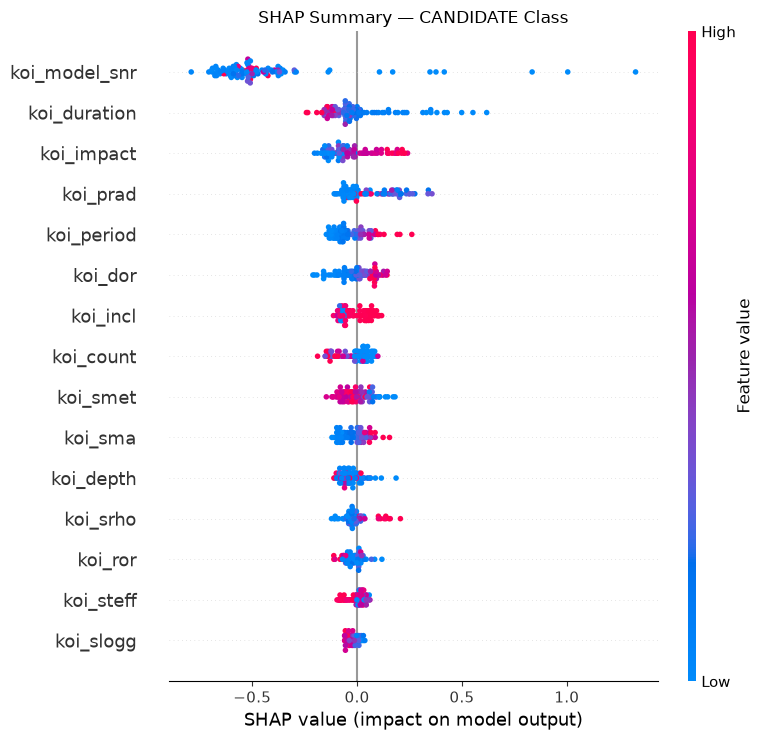

In [16]:
# Prepare feature values for visualization
X_shap_display = pd.DataFrame(
    X_sample,
    columns=catboost_features
)

# Class index: 0 = CANDIDATE
candidate_shap = shap_values[:, 0, :-1]

plt.figure(figsize=(11, 7))

shap.summary_plot(
    candidate_shap,
    X_shap_display,
    max_display=15,
    show=False
)

plt.title("SHAP Summary — CANDIDATE Class")
plt.tight_layout()
plt.show()

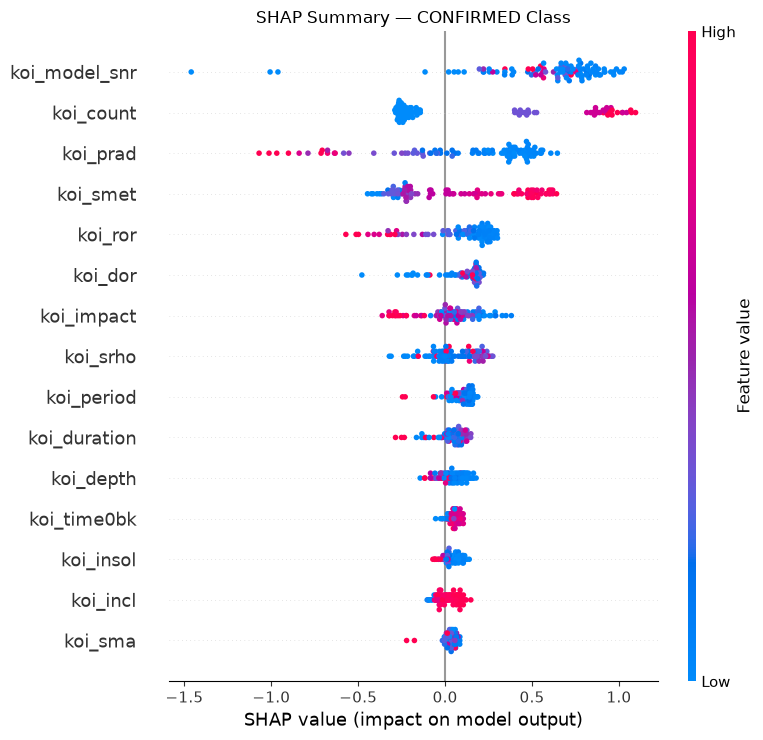

In [17]:
# Class index: 1 = CONFIRMED
confirmed_shap = shap_values[:, 1, :-1]

plt.figure(figsize=(11, 7))

shap.summary_plot(
    confirmed_shap,
    X_shap_display,
    max_display=15,
    show=False
)

plt.title("SHAP Summary — CONFIRMED Class")
plt.tight_layout()
plt.show()

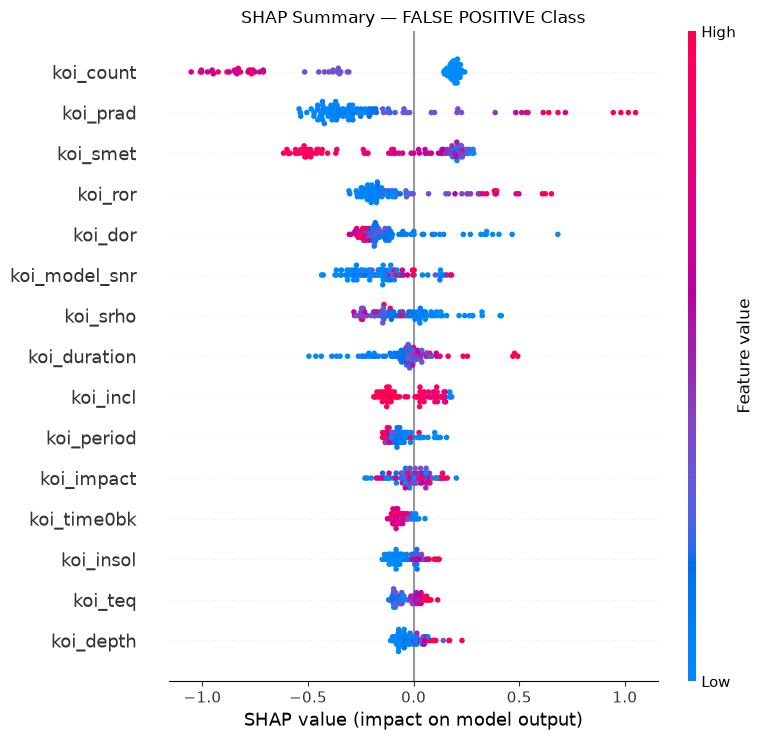

In [18]:
# Class index: 2 = FALSE POSITIVE
false_positive_shap = shap_values[:, 2, :-1]

plt.figure(figsize=(11, 7))

shap.summary_plot(
    false_positive_shap,
    X_shap_display,
    max_display=15,
    show=False
)

plt.title("SHAP Summary — FALSE POSITIVE Class")
plt.tight_layout()
plt.show()

In [19]:
from sklearn.model_selection import StratifiedGroupKFold

from catboost import CatBoostClassifier
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

# Load cleaned Kepler dataset
kepler_clean = pd.read_csv(DATA_DIR / "kepler_clean.csv")

# Original features and target
X = kepler_clean[catboost_features].copy()
y = kepler_clean["koi_disposition"].copy()
groups = kepler_clean["kepid"].copy()

# Recreate original group-aware split
cv = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

train_idx, test_idx = next(
    cv.split(X, y, groups=groups)
)

X_train = X.iloc[train_idx].copy()
X_test = X.iloc[test_idx].copy()

y_train = y.iloc[train_idx].copy()
y_test = y.iloc[test_idx].copy()

# Verify split
print("Training shape:", X_train.shape)
print("Testing shape:", X_test.shape)

print("\nHost-star overlap:",
      len(set(groups.iloc[train_idx]) &
          set(groups.iloc[test_idx])))

print("\nOriginal feature count:", len(catboost_features))

# Remove koi_model_snr
ablation_features = [
    feature for feature in catboost_features
    if feature != "koi_model_snr"
]

X_train_ablated = X_train[ablation_features]
X_test_ablated = X_test[ablation_features]

print("\nFeatures after ablation:", len(ablation_features))
print("Removed feature: koi_model_snr")

assert len(ablation_features) == 30
assert "koi_model_snr" not in ablation_features

print("\nExperiment data prepared successfully!")

Training shape: (7650, 31)
Testing shape: (1914, 31)

Host-star overlap: 0

Original feature count: 31

Features after ablation: 30
Removed feature: koi_model_snr

Experiment data prepared successfully!


In [20]:
# Create CatBoost pipeline without koi_model_snr
ablation_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),

    ("classifier", CatBoostClassifier(
        iterations=500,
        depth=8,
        learning_rate=0.05,
        l2_leaf_reg=5,
        loss_function="MultiClass",
        random_seed=42,
        verbose=0
    ))
])

# Train using 30 features
print("Training CatBoost without koi_model_snr...")

ablation_pipeline.fit(
    X_train_ablated,
    y_train
)

print("Ablation model training completed!")

print("\nModel configuration:")
print("Features:", len(ablation_features))
print("Iterations: 500")
print("Depth: 8")
print("Learning rate: 0.05")

Training CatBoost without koi_model_snr...
Ablation model training completed!

Model configuration:
Features: 30
Iterations: 500
Depth: 8
Learning rate: 0.05


ABLATION MODEL — EVALUATION RESULTS
Accuracy:           0.7738
Balanced Accuracy:  0.7185
Macro Precision:    0.7297
Macro Recall:       0.7185
Macro F1:           0.7198

Classification Report:
                precision    recall  f1-score   support

     CANDIDATE       0.58      0.43      0.50       396
     CONFIRMED       0.78      0.85      0.82       550
FALSE POSITIVE       0.82      0.87      0.84       968

      accuracy                           0.77      1914
     macro avg       0.73      0.72      0.72      1914
  weighted avg       0.76      0.77      0.76      1914



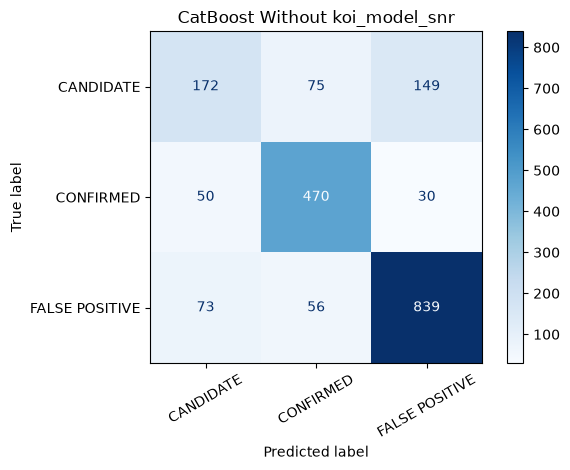

In [21]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# Generate predictions
y_pred_ablated = ablation_pipeline.predict(X_test_ablated)

# Calculate metrics
ablation_accuracy = accuracy_score(y_test, y_pred_ablated)

ablation_balanced_accuracy = balanced_accuracy_score(
    y_test, y_pred_ablated
)

ablation_precision = precision_score(
    y_test, y_pred_ablated,
    average="macro"
)

ablation_recall = recall_score(
    y_test, y_pred_ablated,
    average="macro"
)

ablation_f1 = f1_score(
    y_test, y_pred_ablated,
    average="macro"
)

# Display results
print("ABLATION MODEL — EVALUATION RESULTS")
print("=" * 45)

print(f"Accuracy:           {ablation_accuracy:.4f}")
print(f"Balanced Accuracy:  {ablation_balanced_accuracy:.4f}")
print(f"Macro Precision:    {ablation_precision:.4f}")
print(f"Macro Recall:       {ablation_recall:.4f}")
print(f"Macro F1:           {ablation_f1:.4f}")

print("\nClassification Report:")
print(
    classification_report(
        y_test,
        y_pred_ablated,
        zero_division=0
    )
)

# Confusion matrix
cm_ablated = confusion_matrix(
    y_test,
    y_pred_ablated,
    labels=catboost_classes
)

ConfusionMatrixDisplay(
    confusion_matrix=cm_ablated,
    display_labels=catboost_classes
).plot(cmap="Blues", xticks_rotation=30)

plt.title("CatBoost Without koi_model_snr")
plt.tight_layout()
plt.show()

In [22]:
# Original CatBoost results
original_results = {
    "Model": "Original CatBoost (31 Features)",
    "Accuracy": 0.7947,
    "Balanced Accuracy": 0.7497,
    "Macro Precision": 0.7616,
    "Macro Recall": 0.7497,
    "Macro F1": 0.7527
}

# Ablation CatBoost results
ablation_results = {
    "Model": "Without koi_model_snr (30 Features)",
    "Accuracy": ablation_accuracy,
    "Balanced Accuracy": ablation_balanced_accuracy,
    "Macro Precision": ablation_precision,
    "Macro Recall": ablation_recall,
    "Macro F1": ablation_f1
}

# Comparison DataFrame
ablation_comparison = pd.DataFrame([
    original_results,
    ablation_results
]).set_index("Model")

display(ablation_comparison.round(4))

# Calculate performance differences
performance_drop = (
    ablation_comparison.iloc[0] -
    ablation_comparison.iloc[1]
)

print("\nPERFORMANCE REDUCTION")
print("=" * 35)

display(performance_drop.round(4))

,Accuracy,Balanced Accuracy,Macro Precision,Macro Recall,Macro F1
Model,,,,,
Original CatBoost (31 Features),0.7947,0.7497,0.7616,0.7497,0.7527
Without koi_model_snr (30 Features),0.7738,0.7185,0.7297,0.7185,0.7198



PERFORMANCE REDUCTION


Accuracy             0.0209
Balanced Accuracy    0.0312
Macro Precision      0.0319
Macro Recall         0.0312
Macro F1             0.0329
dtype: float64

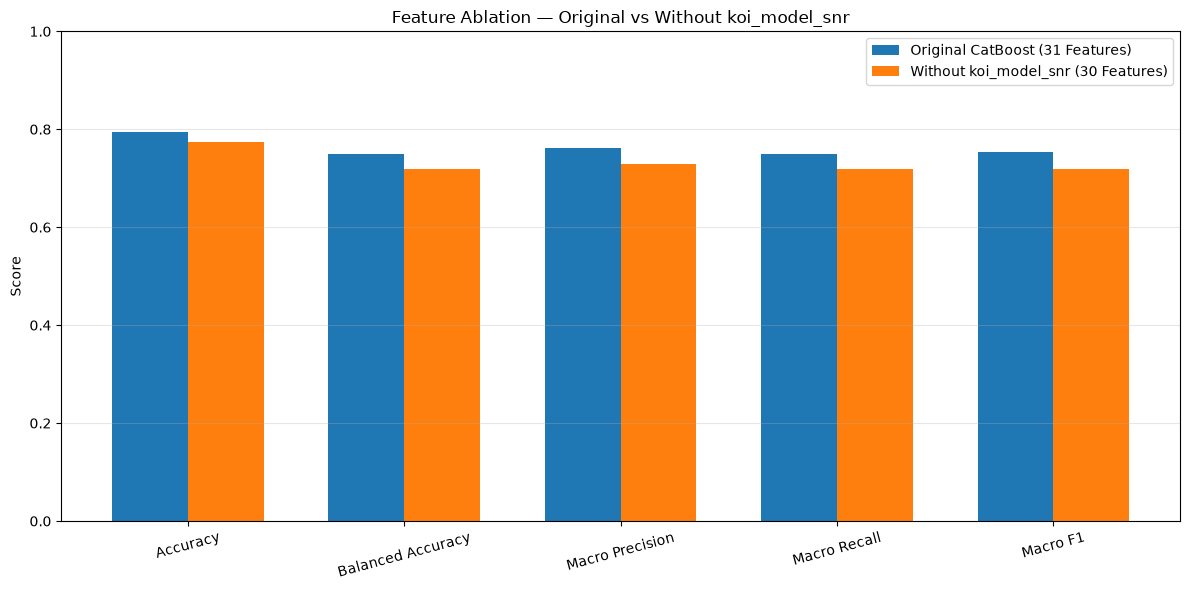

In [23]:
metrics = [
    "Accuracy",
    "Balanced Accuracy",
    "Macro Precision",
    "Macro Recall",
    "Macro F1"
]

original_scores = [
    0.7947, 0.7497, 0.7616, 0.7497, 0.7527
]

ablation_scores = [
    ablation_accuracy,
    ablation_balanced_accuracy,
    ablation_precision,
    ablation_recall,
    ablation_f1
]

x = np.arange(len(metrics))
width = 0.35

plt.figure(figsize=(12, 6))

plt.bar(
    x - width/2,
    original_scores,
    width,
    label="Original CatBoost (31 Features)"
)

plt.bar(
    x + width/2,
    ablation_scores,
    width,
    label="Without koi_model_snr (30 Features)"
)

plt.xticks(x, metrics, rotation=15)
plt.ylabel("Score")
plt.title("Feature Ablation — Original vs Without koi_model_snr")
plt.ylim(0, 1)

plt.legend()
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

In [24]:
import joblib
import json

# Save ablation model
ablation_model_path = MODEL_DIR / "exodetect_catboost_without_snr.pkl"

joblib.dump(
    {
        "pipeline": ablation_pipeline,
        "feature_names": ablation_features,
        "target_classes": list(catboost_classes),
        "model_name": "CatBoost without koi_model_snr",
        "removed_feature": "koi_model_snr"
    },
    ablation_model_path
)

# Prepare experiment results
ablation_results_data = {
    "experiment": "Feature Ablation",
    "baseline_model": "CatBoost",
    "baseline_features": 31,
    "ablated_model": "CatBoost without koi_model_snr",
    "ablated_features": 30,
    "removed_feature": "koi_model_snr",
    "hyperparameters": {
        "iterations": 500,
        "depth": 8,
        "learning_rate": 0.05,
        "l2_leaf_reg": 5,
        "loss_function": "MultiClass",
        "random_seed": 42
    },
    "metrics": {
        "accuracy": float(ablation_accuracy),
        "balanced_accuracy": float(ablation_balanced_accuracy),
        "macro_precision": float(ablation_precision),
        "macro_recall": float(ablation_recall),
        "macro_f1": float(ablation_f1)
    },
    "baseline_macro_f1": 0.7527,
    "macro_f1_reduction": float(0.7527 - ablation_f1)
}

# Save JSON
results_path = DATA_DIR / "feature_ablation_results.json"

with open(results_path, "w") as file:
    json.dump(ablation_results_data, file, indent=4)

print("ABLATION ARTIFACTS SAVED")
print("-" * 40)
print("Model:", ablation_model_path)
print("Results:", results_path)

print("\nBoth artifacts saved successfully!")

ABLATION ARTIFACTS SAVED
----------------------------------------
Model: c:\David Mills\projects\NASAexoplanet\models\exodetect_catboost_without_snr.pkl
Results: c:\David Mills\projects\NASAexoplanet\data\processed\feature_ablation_results.json

Both artifacts saved successfully!


In [25]:
# Reload saved model
loaded_ablation = joblib.load(ablation_model_path)

# Reload experiment results
with open(results_path, "r") as file:
    loaded_results = json.load(file)

print("MODEL VERIFICATION")
print("-" * 40)
print("Model:", loaded_ablation["model_name"])
print("Features:", len(loaded_ablation["feature_names"]))
print("Removed feature:", loaded_ablation["removed_feature"])

print("\nRESULT VERIFICATION")
print("-" * 40)
print("Accuracy:", loaded_results["metrics"]["accuracy"])
print("Macro F1:", loaded_results["metrics"]["macro_f1"])

assert len(loaded_ablation["feature_names"]) == 30
assert "koi_model_snr" not in loaded_ablation["feature_names"]

print("\nALL ABLATION ARTIFACTS VERIFIED!")

MODEL VERIFICATION
----------------------------------------
Model: CatBoost without koi_model_snr
Features: 30
Removed feature: koi_model_snr

RESULT VERIFICATION
----------------------------------------
Accuracy: 0.7737722048066875
Macro F1: 0.7198082602100474

ALL ABLATION ARTIFACTS VERIFIED!


In [26]:
# Prepare final prediction pipeline artifact

prediction_artifact = {
    "pipeline": catboost_pipeline,
    "feature_names": list(catboost_features),
    "target_classes": list(catboost_classes),
    "model_name": "ExoDetect AI - CatBoost",
    "number_of_features": len(catboost_features),
    "preprocessing": "Median Imputation",
    "input_type": "Raw astronomical catalogue features"
}

# Save artifact
prediction_artifact_path = (
    MODEL_DIR / "exodetect_prediction_pipeline.pkl"
)

joblib.dump(
    prediction_artifact,
    prediction_artifact_path
)

print("FINAL PREDICTION PIPELINE SAVED")
print("-" * 45)

print("Model:", prediction_artifact["model_name"])
print("Features:", prediction_artifact["number_of_features"])
print("Classes:", prediction_artifact["target_classes"])
print("Preprocessing:", prediction_artifact["preprocessing"])

print("\nSaved at:", prediction_artifact_path)

FINAL PREDICTION PIPELINE SAVED
---------------------------------------------
Model: ExoDetect AI - CatBoost
Features: 31
Classes: ['CANDIDATE', 'CONFIRMED', 'FALSE POSITIVE']
Preprocessing: Median Imputation

Saved at: c:\David Mills\projects\NASAexoplanet\models\exodetect_prediction_pipeline.pkl


In [29]:
def predict_exoplanet(input_data, artifact=prediction_artifact):

    pipeline = artifact["pipeline"]
    feature_names = artifact["feature_names"]
    target_classes = artifact["target_classes"]

    if not isinstance(input_data, pd.DataFrame):
        raise TypeError("Input must be a Pandas DataFrame.")

    missing_features = [
        feature for feature in feature_names
        if feature not in input_data.columns
    ]

    if missing_features:
        raise ValueError(
            f"Missing required features: {missing_features}"
        )

    X_input = input_data[feature_names].copy()

    # Generate predictions
    predictions = pipeline.predict(X_input).ravel()

    # Generate probabilities
    probabilities = pipeline.predict_proba(X_input)

    results = []

    for i, prediction in enumerate(predictions):

        probability_dict = {
            class_name: float(probabilities[i][j])
            for j, class_name in enumerate(target_classes)
        }

        predicted_class = str(prediction)

        results.append({
            "Predicted Class": predicted_class,
            "Probabilities": probability_dict,
            "Highest Class Probability": float(
                max(probabilities[i])
            )
        })

    return pd.DataFrame(results)

In [30]:
# Select five observations from the test dataset
sample_input = X_test.iloc[:5].copy()

# Generate predictions
sample_predictions = predict_exoplanet(sample_input)

print("EXODETECT AI — SAMPLE PREDICTIONS")
print("=" * 55)

for i in range(len(sample_predictions)):

    print(f"\nObservation {i + 1}")
    print("-" * 35)

    print(
        "Predicted Class:",
        sample_predictions.iloc[i]["Predicted Class"]
    )

    print(
        "Probabilities:",
        sample_predictions.iloc[i]["Probabilities"]
    )

    print(
        "Highest Class Probability:",
        round(
            sample_predictions.iloc[i]["Highest Class Probability"],
            4
        )
    )

EXODETECT AI — SAMPLE PREDICTIONS

Observation 1
-----------------------------------
Predicted Class: FALSE POSITIVE
Probabilities: {'CANDIDATE': 0.04489196119609323, 'CONFIRMED': 0.3671899210340572, 'FALSE POSITIVE': 0.5879181177698496}
Highest Class Probability: 0.5879

Observation 2
-----------------------------------
Predicted Class: CONFIRMED
Probabilities: {'CANDIDATE': 0.03551149469629595, 'CONFIRMED': 0.954133700619009, 'FALSE POSITIVE': 0.010354804684694985}
Highest Class Probability: 0.9541

Observation 3
-----------------------------------
Predicted Class: CONFIRMED
Probabilities: {'CANDIDATE': 0.18058136428805022, 'CONFIRMED': 0.5379499226158273, 'FALSE POSITIVE': 0.28146871309612254}
Highest Class Probability: 0.5379

Observation 4
-----------------------------------
Predicted Class: FALSE POSITIVE
Probabilities: {'CANDIDATE': 0.15825545840713426, 'CONFIRMED': 0.41651692642375165, 'FALSE POSITIVE': 0.42522761516911406}
Highest Class Probability: 0.4252

Observation 5
-----

In [31]:
# Select 100 test observations
X_verification = X_test.iloc[:100].copy()

# Direct model predictions
direct_predictions = (
    prediction_artifact["pipeline"]
    .predict(X_verification)
    .ravel()
)

direct_probabilities = (
    prediction_artifact["pipeline"]
    .predict_proba(X_verification)
)

# Predictions using our reusable function
function_results = predict_exoplanet(X_verification)

function_predictions = function_results[
    "Predicted Class"
].values

function_probabilities = np.array([
    list(probability.values())
    for probability in function_results["Probabilities"]
])

# Compare predictions
predictions_match = np.array_equal(
    direct_predictions.astype(str),
    function_predictions.astype(str)
)

# Compare probabilities
probabilities_match = np.allclose(
    direct_probabilities,
    function_probabilities,
    atol=1e-10
)

print("PREDICTION CONSISTENCY TEST")
print("=" * 45)

print("Observations tested:", len(X_verification))
print("Predictions match:", predictions_match)
print("Probabilities match:", probabilities_match)

assert predictions_match
assert probabilities_match

print("\nALL PREDICTION CONSISTENCY CHECKS PASSED!")

PREDICTION CONSISTENCY TEST
Observations tested: 100
Predictions match: True
Probabilities match: True

ALL PREDICTION CONSISTENCY CHECKS PASSED!


In [32]:
# Test 1: Missing features
try:
    invalid_input = X_test.iloc[:1].drop(
        columns=["koi_period"]
    )

    predict_exoplanet(invalid_input)

except ValueError as e:
    print("TEST 1 PASSED — Missing feature detected")
    print(e)


# Test 2: Incorrect input type
try:
    predict_exoplanet([1, 2, 3])

except TypeError as e:
    print("\nTEST 2 PASSED — Incorrect input type detected")
    print(e)


# Test 3: Valid input containing missing values
try:
    missing_value_input = X_test.iloc[:1].copy()

    missing_value_input.iloc[0, 0] = np.nan

    result = predict_exoplanet(missing_value_input)

    print("\nTEST 3 PASSED — Missing numerical value handled")
    display(result)

except Exception as e:
    print("\nTEST 3 FAILED")
    print(e)

TEST 1 PASSED — Missing feature detected
Missing required features: ['koi_period']

TEST 2 PASSED — Incorrect input type detected
Input must be a Pandas DataFrame.

TEST 3 PASSED — Missing numerical value handled


,Predicted Class,Probabilities,Highest Class Probability
0,FALSE POSITIVE,"{'CANDIDATE': 0.05123151717116034, 'CONFIRMED'...",0.571979


In [33]:
# Batch prediction on the complete Kepler test dataset

batch_predictions = predict_exoplanet(X_test)

# Add actual labels for comparison
batch_predictions["Actual Class"] = y_test.values

# Check output dimensions
print("Batch Prediction Shape:", batch_predictions.shape)

# Compare predicted and actual classes
correct_predictions = (
    batch_predictions["Predicted Class"] ==
    batch_predictions["Actual Class"]
).sum()

total_predictions = len(batch_predictions)

print("\nTotal Predictions:", total_predictions)
print("Correct Predictions:", correct_predictions)
print("Incorrect Predictions:", total_predictions - correct_predictions)

print(
    "\nPrediction Agreement:",
    round(correct_predictions / total_predictions * 100, 2),
    "%"
)

# Display prediction distribution
print("\nPredicted Class Distribution:")
display(batch_predictions["Predicted Class"].value_counts())

# Display sample predictions
display(batch_predictions.head(10))

Batch Prediction Shape: (1914, 4)

Total Predictions: 1914
Correct Predictions: 1521
Incorrect Predictions: 393

Prediction Agreement: 79.47 %

Predicted Class Distribution:


Predicted Class
FALSE POSITIVE    1013
CONFIRMED          587
CANDIDATE          314
Name: count, dtype: int64

,Predicted Class,Probabilities,Highest Class Probability,Actual Class
0,FALSE POSITIVE,"{'CANDIDATE': 0.04489196119609323, 'CONFIRMED'...",0.587918,CONFIRMED
1,CONFIRMED,"{'CANDIDATE': 0.03551149469629595, 'CONFIRMED'...",0.954134,CONFIRMED
2,CONFIRMED,"{'CANDIDATE': 0.18058136428805022, 'CONFIRMED'...",0.537950,CONFIRMED
3,FALSE POSITIVE,"{'CANDIDATE': 0.15825545840713426, 'CONFIRMED'...",0.425228,FALSE POSITIVE
4,CONFIRMED,"{'CANDIDATE': 0.030859746221254484, 'CONFIRMED...",0.867764,CONFIRMED
5,CONFIRMED,"{'CANDIDATE': 0.03492950640888421, 'CONFIRMED'...",0.827832,CONFIRMED
6,CONFIRMED,"{'CANDIDATE': 0.017935068154574855, 'CONFIRMED...",0.960819,CONFIRMED
7,CONFIRMED,"{'CANDIDATE': 0.012505347305887959, 'CONFIRMED...",0.979334,CONFIRMED
8,CONFIRMED,"{'CANDIDATE': 0.010142355396877736, 'CONFIRMED...",0.982069,CONFIRMED
9,CONFIRMED,"{'CANDIDATE': 0.01188023589669946, 'CONFIRMED'...",0.978191,CONFIRMED


In [34]:
# Save batch prediction results

PREDICTION_OUTPUT_PATH = DATA_DIR / "kepler_batch_predictions.csv"

batch_predictions.to_csv(
    PREDICTION_OUTPUT_PATH,
    index=False
)

print("Batch predictions saved successfully!")
print("Location:", PREDICTION_OUTPUT_PATH)

# Verify saved file
saved_predictions = pd.read_csv(PREDICTION_OUTPUT_PATH)

print("\nSaved Dataset Shape:", saved_predictions.shape)
print("Missing Values:", saved_predictions.isnull().sum().sum())

print("\nSaved Prediction Sample:")
display(saved_predictions.head())

Batch predictions saved successfully!
Location: c:\David Mills\projects\NASAexoplanet\data\processed\kepler_batch_predictions.csv

Saved Dataset Shape: (1914, 4)
Missing Values: 0

Saved Prediction Sample:


,Predicted Class,Probabilities,Highest Class Probability,Actual Class
0,FALSE POSITIVE,"{'CANDIDATE': 0.04489196119609323, 'CONFIRMED'...",0.587918,CONFIRMED
1,CONFIRMED,"{'CANDIDATE': 0.03551149469629595, 'CONFIRMED'...",0.954134,CONFIRMED
2,CONFIRMED,"{'CANDIDATE': 0.18058136428805022, 'CONFIRMED'...",0.537950,CONFIRMED
3,FALSE POSITIVE,"{'CANDIDATE': 0.15825545840713426, 'CONFIRMED'...",0.425228,FALSE POSITIVE
4,CONFIRMED,"{'CANDIDATE': 0.030859746221254484, 'CONFIRMED...",0.867764,CONFIRMED


In [35]:
# Final model artifact verification

required_model_files = [
    "exodetect_catboost_final.pkl",
    "exodetect_weighted_mlp.pth",
    "exodetect_prediction_pipeline.pkl",
    "exodetect_catboost_without_snr.pkl",
    "exodetect_catboost_9feature_tess_validation.pkl",
    "exodetect_domain_classifier.pkl",
    "kepler_preprocessing_pipeline.pkl",
    "dl_feature_names.json",
    "dl_imputer.pkl",
    "dl_label_encoder.pkl",
    "dl_scaler.pkl",
    "weighted_mlp_results.json",
    "tess_validation_results.json"
]

required_data_files = [
    "feature_ablation_results.json",
    "kepler_batch_predictions.csv",
    "tess_external_predictions.csv",
    "domain_shift_summary.csv"
]

print("=" * 55)
print("MODEL ARTIFACT VERIFICATION")
print("=" * 55)

missing_models = []

for filename in required_model_files:
    file_path = MODEL_DIR / filename

    if file_path.exists():
        print(f"FOUND: {filename}")
    else:
        print(f"MISSING: {filename}")
        missing_models.append(filename)

print("\n" + "=" * 55)
print("PROCESSED DATA ARTIFACT VERIFICATION")
print("=" * 55)

missing_data = []

for filename in required_data_files:
    file_path = DATA_DIR / filename

    if file_path.exists():
        print(f"FOUND: {filename}")
    else:
        print(f"MISSING: {filename}")
        missing_data.append(filename)

print("\n" + "=" * 55)

if not missing_models and not missing_data:
    print("SUCCESS: ALL REQUIRED ARTIFACTS VERIFIED!")
else:
    print("VERIFICATION INCOMPLETE")
    print("Missing model files:", missing_models)
    print("Missing data files:", missing_data)

MODEL ARTIFACT VERIFICATION
FOUND: exodetect_catboost_final.pkl
FOUND: exodetect_weighted_mlp.pth
FOUND: exodetect_prediction_pipeline.pkl
FOUND: exodetect_catboost_without_snr.pkl
FOUND: exodetect_catboost_9feature_tess_validation.pkl
FOUND: exodetect_domain_classifier.pkl
FOUND: kepler_preprocessing_pipeline.pkl
FOUND: dl_feature_names.json
FOUND: dl_imputer.pkl
FOUND: dl_label_encoder.pkl
FOUND: dl_scaler.pkl
FOUND: weighted_mlp_results.json
FOUND: tess_validation_results.json

PROCESSED DATA ARTIFACT VERIFICATION
FOUND: feature_ablation_results.json
FOUND: kepler_batch_predictions.csv
FOUND: tess_external_predictions.csv
FOUND: domain_shift_summary.csv

SUCCESS: ALL REQUIRED ARTIFACTS VERIFIED!


# 12. Final Conclusion

## 12.1 Overview

This notebook focused on finalizing the ExoDetect AI machine learning system, comparing its trained models, understanding model behavior through explainability techniques, conducting feature ablation experiments, and developing a reusable prediction pipeline.

The primary model selected for ExoDetect AI is CatBoost, trained using 31 astronomical catalogue features from the NASA Kepler dataset.

## 12.2 Model Comparison

Two models were evaluated using the same group-aware Kepler test split.

| Metric | CatBoost | Weighted MLP |
|---|---:|---:|
| Accuracy | 79.47% | 69.49% |
| Balanced Accuracy | 74.97% | 67.73% |
| Macro Precision | 76.16% | 66.58% |
| Macro Recall | 74.97% | 67.73% |
| Macro F1-score | 75.27% | 66.41% |

CatBoost achieved better performance across all reported metrics and was selected as the primary classification model.

The weighted MLP was retained as a deep learning comparison model.

## 12.3 Model Explainability

CatBoost built-in feature importance and SHAP analysis were used to understand the contribution of astronomical features to model predictions.

The most influential features included:

- `koi_model_snr`
- `koi_count`
- `koi_prad`
- `koi_smet`
- `koi_ror`
- `koi_dor`
- `koi_duration`
- `koi_impact`

The Signal-to-Noise Ratio (`koi_model_snr`) was the most influential feature in both analyses.

SHAP analysis was conducted using a sample of 100 observations and examined contributions to the model's individual class outputs.

These explanations describe model behavior and should not be interpreted as causal astronomical relationships.

## 12.4 Feature Ablation Experiment

A feature ablation experiment was conducted by removing `koi_model_snr` and retraining CatBoost with the remaining 30 features.

| Metric | Original Model | Without SNR |
|---|---:|---:|
| Accuracy | 79.47% | 77.38% |
| Balanced Accuracy | 74.97% | 71.85% |
| Macro Precision | 76.16% | 72.97% |
| Macro Recall | 74.97% | 71.85% |
| Macro F1-score | 75.27% | 71.98% |

Removing `koi_model_snr` reduced Macro F1-score by approximately 3.29 percentage points.

This indicates that the feature contributes useful predictive information. However, the remaining features also retain substantial predictive capability.

The experiment was conducted using one fixed train-test split and fixed hyperparameters.

## 12.5 Final Prediction Pipeline

A reusable prediction pipeline was developed using the finalized CatBoost model.

The pipeline:

1. Accepts raw astronomical catalogue features in a Pandas DataFrame.
2. Checks whether all required features are present.
3. Applies the trained median imputation process.
4. Predicts the exoplanet disposition.
5. Returns probabilities for all three classes.
6. Returns the highest class probability for each observation.

The prediction function was tested for:

- Single-observation predictions.
- Batch predictions.
- Missing required features.
- Incorrect input data types.
- Missing numerical values.
- Prediction consistency with the original CatBoost pipeline.

All input-validation and prediction-consistency tests passed.

## 12.6 Batch Prediction Results

The finalized prediction pipeline was evaluated on all 1,914 observations in the Kepler test dataset.

| Result | Value |
|---|---:|
| Total predictions | 1,914 |
| Correct predictions | 1,521 |
| Incorrect predictions | 393 |
| Prediction agreement | 79.47% |

The predictions were successfully exported to:

`data/processed/kepler_batch_predictions.csv`

## 12.7 Artifact Verification

All required model and supporting data artifacts were verified successfully.

Important artifacts include:

- Final CatBoost model.
- Weighted MLP model.
- Nine-feature Kepler-trained model for TESS validation.
- Domain classifier.
- Feature-ablation model.
- Reusable prediction pipeline.
- Preprocessing and deep learning components.
- TESS validation results.
- Feature-ablation results.
- Kepler batch predictions.
- TESS external predictions.

All required files were found in their expected directories.

## 12.8 Final Conclusion

ExoDetect AI now contains a finalized CatBoost classification model, a deep learning comparison model, model explainability analysis, feature ablation experiments, and a reusable prediction pipeline.

The CatBoost model achieved a test accuracy of 79.47% and a Macro F1-score of 75.27% on the Kepler test dataset.

However, the cross-mission validation conducted in Notebook 06 revealed substantial domain shift between Kepler and TESS catalogue data. Therefore, the Kepler model's performance should not be assumed to transfer directly to TESS observations.

The prediction pipeline is now ready to serve as the foundation for the ExoDetect AI application.

**Notebook 07 completed successfully.**

In [1]:
import pandas as pd
from pathlib import Path

PROJECT_ROOT = Path(r"C:\David Mills\projects\NASAexoplanet")

domain_shift_df = pd.read_csv(
    PROJECT_ROOT / "data" / "processed" / "domain_shift_summary.csv"
)

print("Shape:", domain_shift_df.shape)
print("\nColumns:")
print(domain_shift_df.columns.tolist())

print("\nFirst 10 rows:")
display(domain_shift_df.head(10))

Shape: (9, 9)

Columns:
['Feature', 'Kepler Median', 'TESS Median', 'Kepler IQR', 'TESS IQR', 'KS Statistic', 'KS p-value', 'Kepler Missing (%)', 'TESS Missing (%)']

First 10 rows:


,Feature,Kepler Median,TESS Median,Kepler IQR,TESS IQR,KS Statistic,KS p-value,Kepler Missing (%),TESS Missing (%)
0,koi_depth,418.30000,4418.000000,1263.000000,8351.886006,0.514242,0.000000e+00,3.751634,0.000000
1,koi_prad,2.37000,10.072200,12.830000,9.433262,0.422824,0.000000e+00,3.751634,6.741251
2,koi_period,9.91831,4.260780,38.071077,5.819971,0.295624,1.271489e-279,0.000000,1.333907
3,koi_duration,3.79210,2.790520,3.847190,2.001586,0.244205,2.538041e-191,0.000000,0.057372
4,koi_srad,0.99700,1.240000,0.504000,0.785274,0.226933,6.347629e-155,3.751634,8.290304
5,koi_teq,873.00000,1179.000000,835.500000,795.859289,0.216580,1.181979e-144,3.751634,3.786575
6,koi_slogg,4.44000,4.330000,0.322500,0.386090,0.188615,7.106692e-105,3.751634,11.460126
7,koi_insol,138.51000,353.894099,824.110000,1106.740300,0.179782,1.662017e-100,3.307190,2.452668
8,koi_steff,5765.00000,5801.200000,799.500000,1106.910000,0.106399,2.573033e-35,3.751634,2.337923
